In [2]:
import numpy as np
import matplotlib.pyplot as plt

#### Exercise 1.

In [105]:
def add_noise(Y, mu, sigma, sample_size, dims=1):
    epsilon = np.random.normal(loc=mu, scale = sigma, size=(sample_size,dims))
    Y = Y + epsilon
    return Y
    
def compute_leverage_scores(X, Y, sample_size, dims=1):

    # compute the hat matrix
    if dims == 1:
        X = X.reshape(-1,1)
    H = X @ np.linalg.inv(X.T @ X) @ X.T
    # print(H.shape)

    # extract leverage scores
    leverage_scores = np.diagonal(H)
    # print(leverage_scores.shape)

    # sanity check
    sum_lev = np.sum(leverage_scores)
    # print(sum_lev) # for 1D case, should be 1

    # a "high" leverage score is considered bigger than 2 * d/n; in our case, d=2 and n=250
    avg_lev = 2 / sample_size
    top_scores_idx = np.where(leverage_scores > 2 * avg_lev)

    X_high = X[top_scores_idx]
    Y_high = Y[top_scores_idx]


    return X, Y, X_high, Y_high, leverage_scores

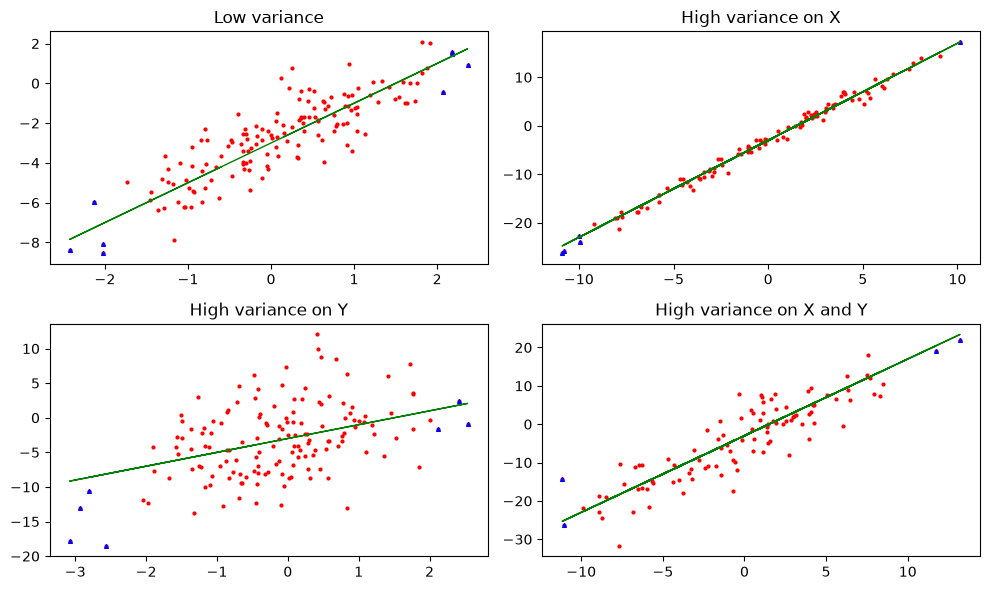

In [96]:
params = [(0, 1), (0, 1), (0, 5), (0, 5)]
titles = ["Low variance", "High variance on X", "High variance on Y", "High variance on X and Y"]
a, b = 2 , -3 # the slope and intercept of the linear model
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes = axes.flatten()

for i, p in enumerate(params):
    if i % 2 == 1: # cases for points with high variance
        sample_size=100
        X = np.random.normal(0, 5, size=(sample_size,1)) # mean 0, stddev 5
    else:
        sample_size=150
        X = np.random.normal(size=(sample_size,1)) # mean 0, stddev 1
    Y = a * X + b # the regression line 
    Y = add_noise(Y, mu=p[0], sigma=p[1], sample_size=sample_size)
    X, Y, X_high, Y_high, _ = compute_leverage_scores(X, Y, sample_size)
    axes[i].plot(X, a * X + b, c='green', linewidth=1)
    axes[i].scatter(X, Y, c='red', marker='o', s=4)
    axes[i].scatter(X_high, Y_high, c='blue', marker='^', s=7)
    # axes[i].xlabel("Feature X")
    # axes[i].ylabel("Label Y")
    axes[i].set_title(titles[i])

plt.tight_layout()
plt.show()


Now, for the 2D case: $y = ax_{1} + bx_{2} + c + \epsilon $

Firstly I tried to visualize the points in the original plane before applying any noise:

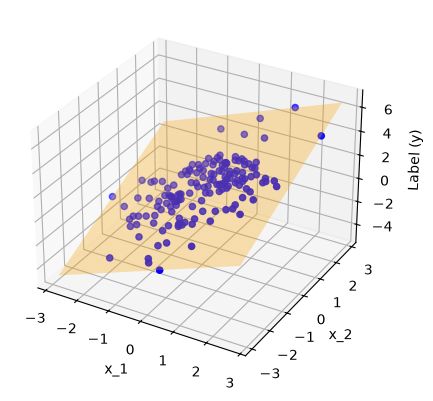

In [94]:
sample_size = 150
X = np.random.normal(size=(sample_size,2))

a, b, c = 1, 1, 1
y = a * X[:, 0] + b * X[:, 1] + c

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

# Generate the plane
x1 = np.linspace(X[:, 0].min(), X[:, 0].max(), 20)
x2 = np.linspace(X[:, 1].min(), X[:, 1].max(), 20)
X1, X2 = np.meshgrid(x1, x2)
Y = a * X1 + b * X2 + c
ax.plot_surface(X1, X2, Y, alpha=0.3, color='orange')

# plot the points 

ax.scatter(X[:, 0], X[:, 1], y, color='blue')
ax.set_xlabel('x_1')
ax.set_ylabel('x_2') 
ax.set_zlabel('Label (y)')
plt.show()

(150,)
(150, 1)
(150, 2) (150, 1) (19, 2) (19, 1)
(100,)
(100, 1)
(100, 2) (100, 1) (13, 2) (13, 1)
(150,)
(150, 1)
(150, 2) (150, 1) (22, 2) (22, 1)
(100,)
(100, 1)
(100, 2) (100, 1) (15, 2) (15, 1)


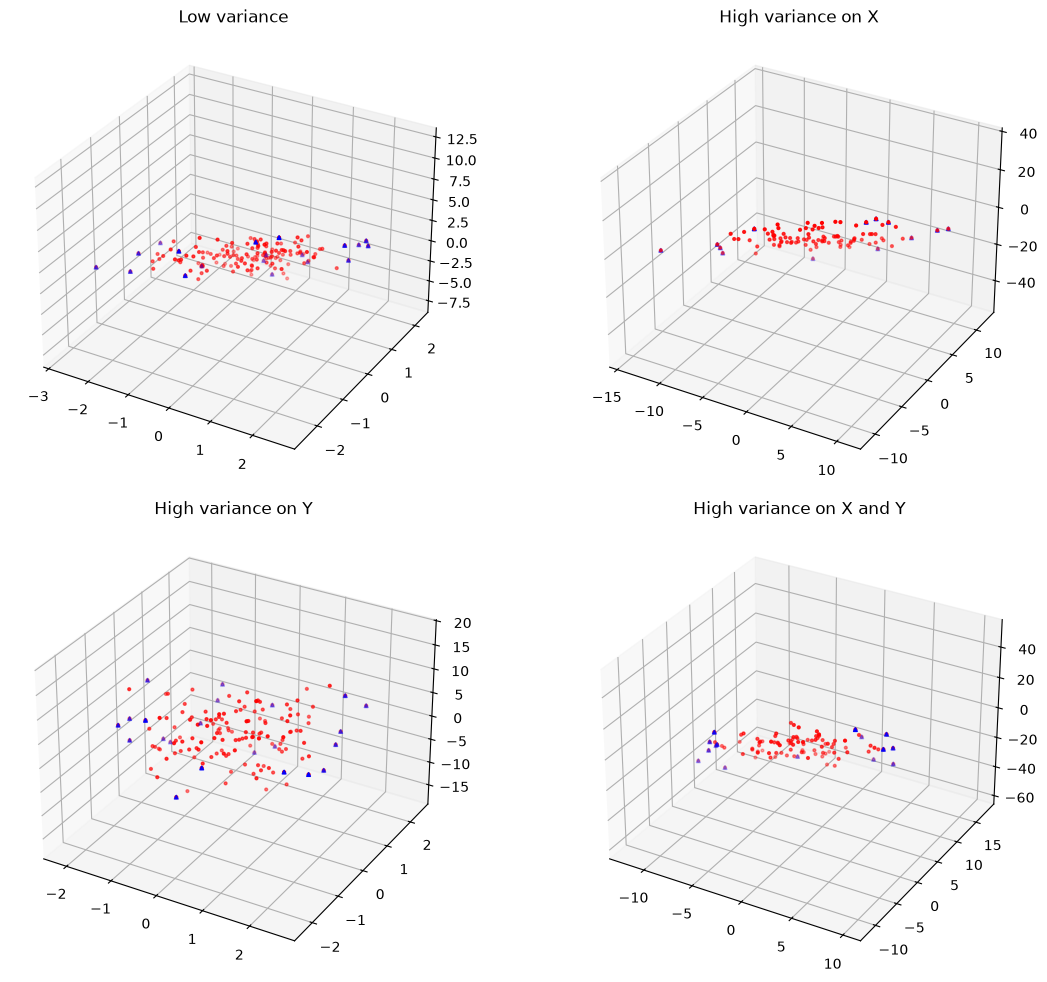

In [114]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10),
    subplot_kw={'projection': '3d'}
)
axes = axes.flatten()
params = [(0, 1), (0, 1), (0, 5), (0, 5)]
titles = ["Low variance", "High variance on X", "High variance on Y", "High variance on X and Y"]

for i, p in enumerate(params):
    if i % 2 == 1: 
        sample_size=100
        X = np.random.normal(0, 5, size=(sample_size,2)) # mean 0, stddev 5
    else:
        sample_size=150
        X = np.random.normal(size=(sample_size,2)) # mean 0, stddev 1
    Y = a * X[:, 0] + b * X[:, 1] + c
    print(Y.shape)
    Y = Y.reshape(-1, 1)
    Y = add_noise(Y, mu=p[0], sigma=p[1], sample_size=sample_size)
    print(Y.shape)
    X, Y, X_high, Y_high, _ = compute_leverage_scores(X, Y, sample_size, dims=2)

    print(X.shape, Y.shape, X_high.shape, Y_high.shape)
    
    axes[i].scatter(X[:, 0], X[:, 1], Y.ravel(), c='red', marker='o', s=4)
    axes[i].scatter(X_high[:, 0], X_high[:, 1], Y_high.ravel(), c='blue', marker='^', s=7)
    axes[i].set_title(titles[i])

plt.tight_layout()
plt.show()

#### Exercise 2.


d:\Facultate\Master\Anul I Sem I\Anomaly Detection (AD)\Lab\.venv\Lib\site-packages\pyod\models\base.py:555: UserWarning: y should not be presented in unsupervised learning.
  warnings.warn(


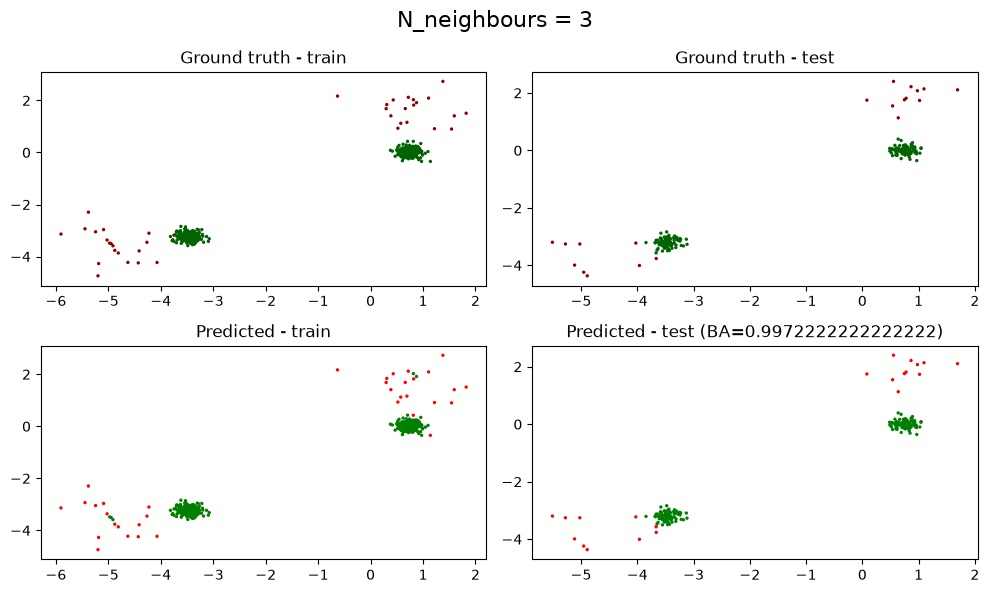

d:\Facultate\Master\Anul I Sem I\Anomaly Detection (AD)\Lab\.venv\Lib\site-packages\pyod\models\base.py:555: UserWarning: y should not be presented in unsupervised learning.
  warnings.warn(


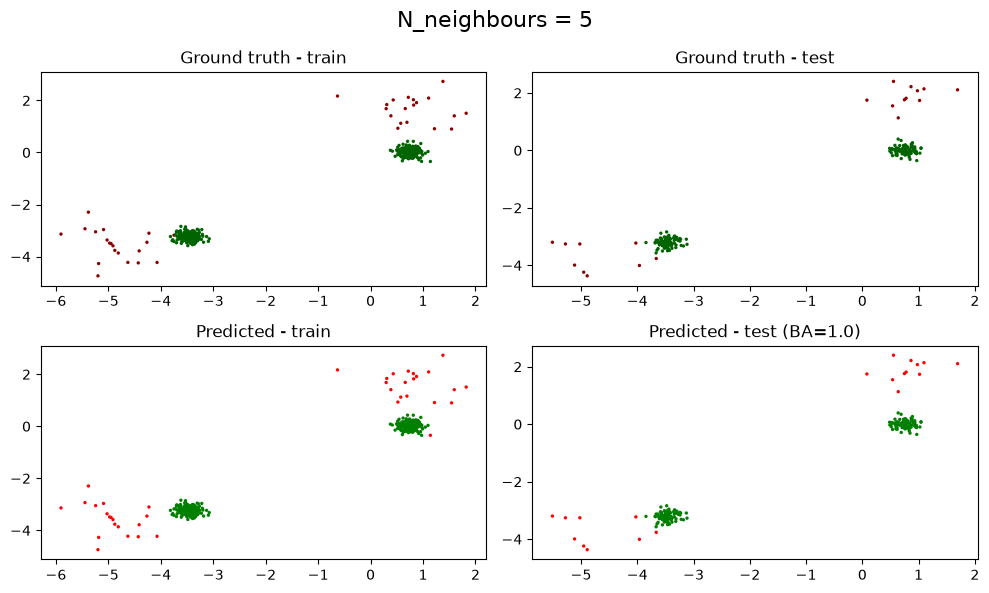

d:\Facultate\Master\Anul I Sem I\Anomaly Detection (AD)\Lab\.venv\Lib\site-packages\pyod\models\base.py:555: UserWarning: y should not be presented in unsupervised learning.
  warnings.warn(


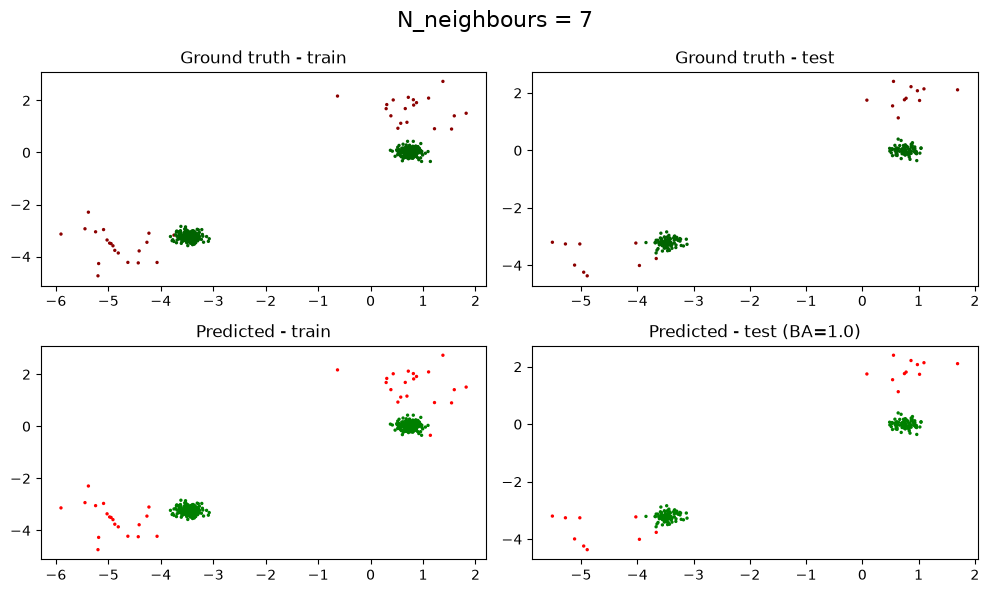

d:\Facultate\Master\Anul I Sem I\Anomaly Detection (AD)\Lab\.venv\Lib\site-packages\pyod\models\base.py:555: UserWarning: y should not be presented in unsupervised learning.
  warnings.warn(


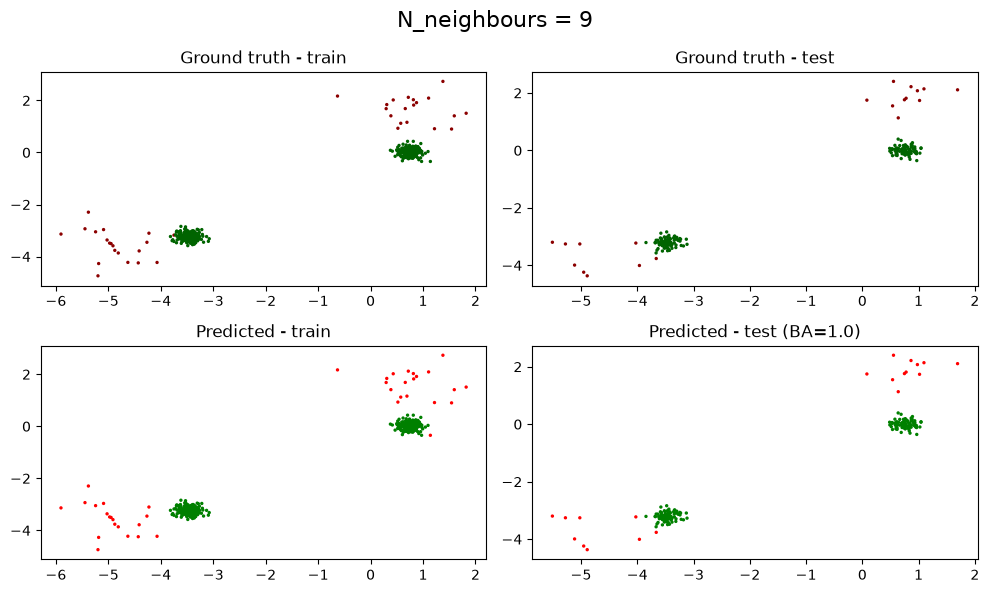

In [ ]:
from pyod.utils.data import generate_data_clusters
from pyod.models import knn
from sklearn.metrics import confusion_matrix

X_train, X_test, y_train, y_test = generate_data_clusters(n_train=400, n_test=200, n_clusters=2, n_features=2, contamination=0.1)

# outliers are labeled with 1, inliers with 0

colors_train = np.where(y_train == 0, 'darkgreen', 'darkred')
colors_test = np.where(y_test == 0, 'darkgreen', 'darkred')

def knn_model(num_neigh, X_train, X_test, y_train, y_test):
    model = knn.KNN(contamination=0.1, n_neighbors=num_neigh)
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_test_pred)

    TN, FP, FN, TP = cm[0,0], cm[0,1], cm[1,0], cm[1,1]  # computing the metrics on the test set
    TPR = TP / (TP + FN) # sensitivity / recall
    TNR = TN / (TN + FP) # specificity
    BA = (TPR + TNR) / 2 # balanced accuracy

    return y_train_pred, y_test_pred, BA

N = [3, 5, 7, 9]

for num_neighbours in N:
    y_train_pred, y_test_pred, BA = knn_model(num_neighbours, X_train, X_test, y_train, y_test)
    colors_train_pred = np.where(y_train_pred == 0, 'green', 'red')
    colors_test_pred = np.where(y_test_pred == 0, 'green', 'red')

    fig, axes = plt.subplots(2, 2, figsize=(10, 6))
    axes = axes.flatten()

    axes[0].scatter(X_train[:, 0], X_train[:, 1], c=colors_train, s=2)
    axes[0].set_title("Ground truth - train")

    axes[1].scatter(X_test[:, 0], X_test[:, 1], c=colors_test, s=2)
    axes[1].set_title("Ground truth - test")

    axes[2].scatter(X_train[:, 0], X_train[:, 1], c=colors_train_pred, s=2)
    axes[2].set_title("Predicted - train")

    axes[3].scatter(X_test[:, 0], X_test[:, 1], c=colors_test_pred, s=2)
    axes[3].set_title(f"Predicted - test (BA={BA})")


    fig.suptitle(f'N_neighbours = {num_neighbours}', fontsize=16)

    plt.tight_layout()
    plt.show()

#### Exercise 3.

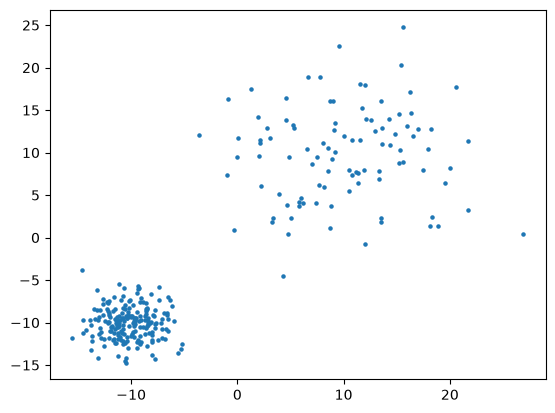

In [128]:
from sklearn.datasets import make_blobs
from pyod.models import lof

X, y = make_blobs(n_samples=(200, 100), n_features=2, centers=((-10, -10), (10, 10)), cluster_std=(2.0, 6.0))

# checked the data generatiom
fig = plt.figure()
ax = fig.add_subplot()
ax.scatter(X[:, 0], X[:, 1], s=5)
plt.show()

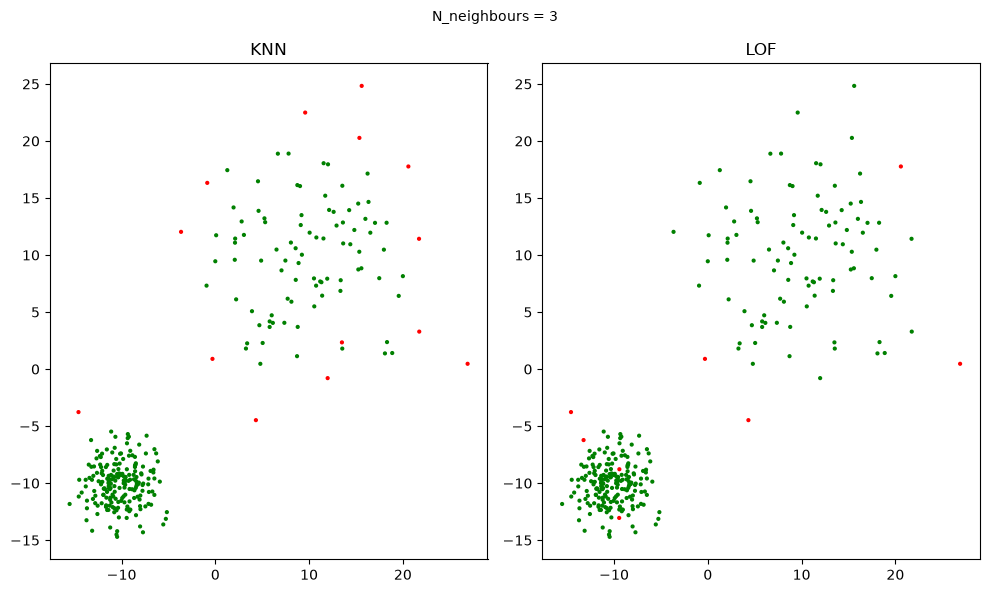

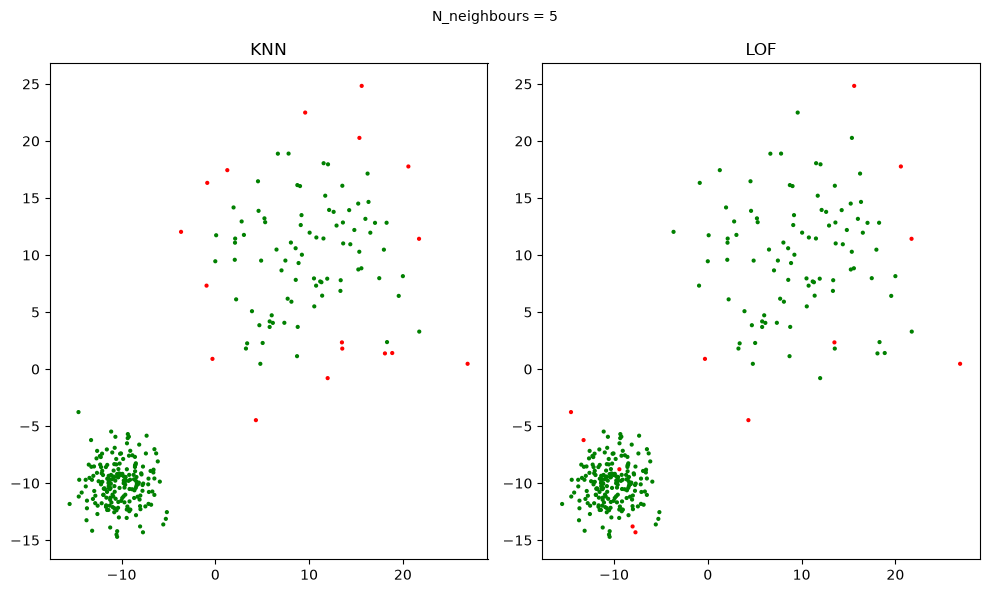

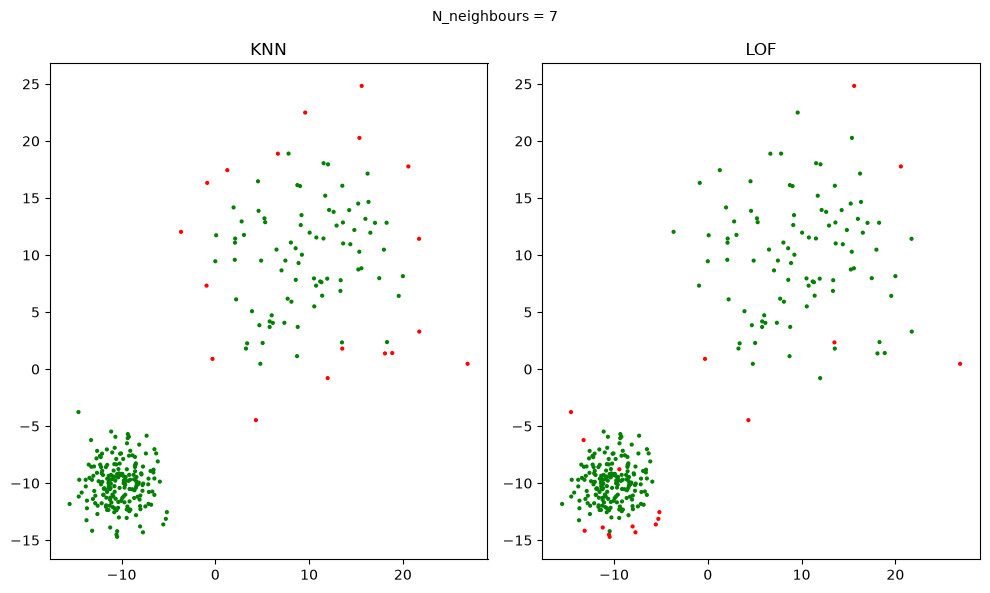

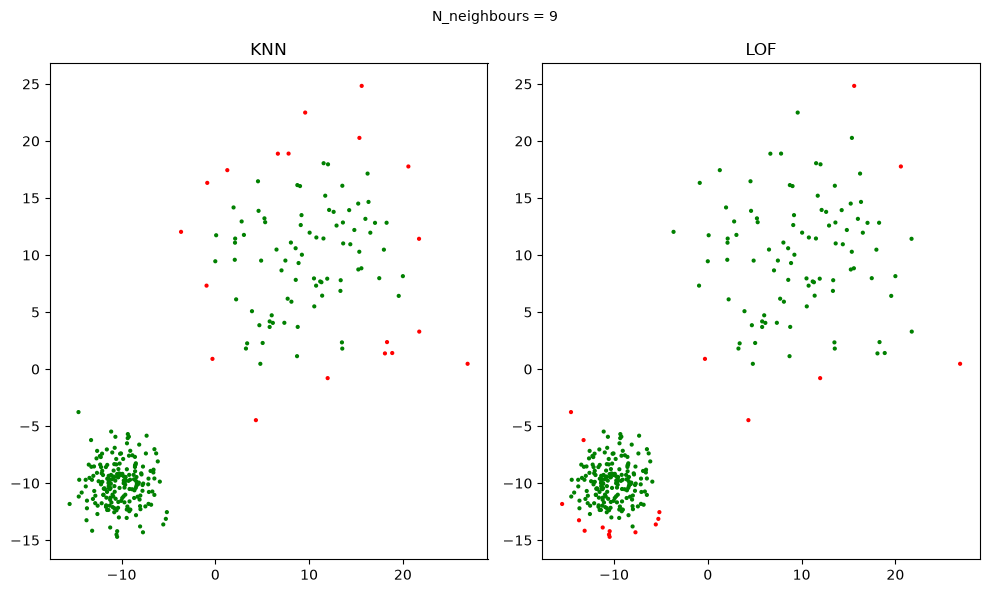

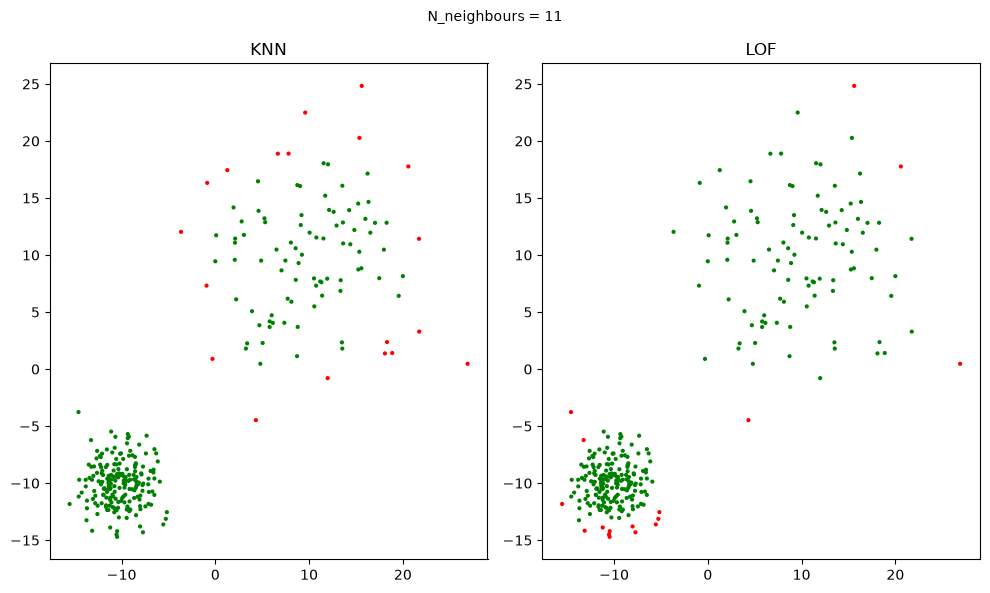

In [133]:
def compare_knn_lof(num_neighbours, X_train):
    knn_model = knn.KNN(contamination=0.07, n_neighbors=num_neighbours)
    # in the unsupervised setting, no y_train labels are provided
    knn_model.fit(X_train)
    y_pred_knn = knn_model.predict(X_train)

    lof_model = lof.LOF(n_neighbors=num_neighbours, contamination=0.07)
    lof_model.fit(X_train)
    y_pred_lof = lof_model.predict(X_train)

    return y_pred_knn, y_pred_lof


N = [3, 5, 7, 9, 11]

for num_neighbours in N:
    y_pred_knn, y_pred_lof = compare_knn_lof(num_neighbours, X)
    colors_knn_pred = np.where(y_pred_knn == 0, 'green', 'red')
    colors_lof_pred = np.where(y_pred_lof == 0, 'green', 'red')

    fig, axes = plt.subplots(1, 2, figsize=(10, 6))
    axes = axes.flatten()

    axes[0].scatter(X[:, 0], X[:, 1], c=colors_knn_pred, s=4)
    axes[0].set_title("KNN")

    axes[1].scatter(X[:, 0], X[:, 1], c=colors_lof_pred, s=4)
    axes[1].set_title("LOF")

    fig.suptitle(f'N_neighbours = {num_neighbours}', fontsize=10)

    plt.tight_layout()
    plt.show()

#### Exercise 4.


In [163]:
from scipy.io import loadmat
from sklearn.model_selection import train_test_split
from pyod.utils.utility import standardizer
from sklearn.preprocessing import StandardScaler
from pyod.models.combination import average, maximization

dicti = loadmat('cardio.mat')
X = dicti['X']
y = dicti['y']

print(X.shape)
print(y.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

scaler = StandardScaler()
X_train_norm = scaler.fit_transform(X_train)
X_test_norm = scaler.transform(X_test)

outliers_cnt = np.count_nonzero(y)
print(outliers_cnt)
contamination_rate = outliers_cnt / y.shape[0]
print(contamination_rate)

(1831, 21)
(1831, 1)
176
0.0961223375204806


In [164]:
def compute_BA(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    TN, FP, FN, TP = cm[0,0], cm[0,1], cm[1,0], cm[1,1]  
    TPR = TP / (TP + FN) 
    TNR = TN / (TN + FP) 
    BA = (TPR + TNR) / 2
    return BA

def run_lof(num_neighbours, X_train, y_train, X_test, y_test, cr):
    
    lof_model = lof.LOF(n_neighbors=num_neighbours, contamination=cr)
    lof_model.fit(X_train)
    y_pred_train = lof_model.predict(X_train)
    y_pred_test = lof_model.predict(X_test)

    BA_train = compute_BA(y_train, y_pred_train)
    BA_test = compute_BA(y_test, y_pred_test)

    scores_train = lof_model.decision_scores_
    scores_test = lof_model.decision_function(X_test)

    return BA_train, BA_test, scores_train, scores_test


N = np.arange(100, 200, 10)
train_scores, test_scores = [], []
for n in N:
    BA_train, BA_test, scores_train, scores_test = run_lof(n, X_train, y_train, X_test, y_test, contamination_rate)

    train_scores.append(scores_train)
    test_scores.append(scores_test)

    print(f'Num neighbours = {n} -> BA_train = {BA_train: .4f}, BA_test = {BA_test: .4f}')

train_scores = np.column_stack(train_scores)
test_scores = np.column_stack(test_scores)

print(train_scores.shape)  
print(test_scores.shape)   


Num neighbours = 100 -> BA_train =  0.6115, BA_test =  0.6459
Num neighbours = 110 -> BA_train =  0.6326, BA_test =  0.6564
Num neighbours = 120 -> BA_train =  0.6433, BA_test =  0.6668
Num neighbours = 130 -> BA_train =  0.6718, BA_test =  0.6876
Num neighbours = 140 -> BA_train =  0.6882, BA_test =  0.7097
Num neighbours = 150 -> BA_train =  0.6945, BA_test =  0.7097
Num neighbours = 160 -> BA_train =  0.7231, BA_test =  0.7213
Num neighbours = 170 -> BA_train =  0.7274, BA_test =  0.7225
Num neighbours = 180 -> BA_train =  0.7274, BA_test =  0.7341
Num neighbours = 190 -> BA_train =  0.7282, BA_test =  0.7341
(1373, 10)
(458, 10)


In [172]:
train_scores_norm, test_scores_norm = standardizer(train_scores,test_scores)
train_avg = average(train_scores_norm)
test_avg = average(test_scores_norm)

train_max = maximization(train_scores_norm)
test_max = maximization(test_scores_norm)

# averaging
threshold_avg = np.quantile(train_avg, 1 - contamination_rate)

y_pred_train_avg = (train_avg > threshold_avg).astype(int)
y_pred_test_avg = (test_avg > threshold_avg).astype(int)

# maximizing
threshold_max = np.quantile(train_max, 1 - contamination_rate)

y_pred_train_max = (train_max > threshold_max).astype(int)
y_pred_test_max = (test_max > threshold_max).astype(int)

# print(y_pred_train_avg.shape, y_pred_test_avg.shape)
# print(y_pred_train_max.shape, y_pred_test_max.shape)


avg_strat_thresh = np.quantile(train_avg, 1-contamination_rate)
max_strat_thresh = np.quantile(train_max, 1-contamination_rate)

BA_train_avg = compute_BA(y_train.ravel(), y_pred_train_avg)
BA_test_avg = compute_BA(y_test.ravel(), y_pred_test_avg)

BA_train_max = compute_BA(y_train.ravel(), y_pred_train_max)
BA_test_max = compute_BA(y_test.ravel(), y_pred_test_max)

print('Averaging:')
print(f'Balanced Accuracy - Train: {BA_train_avg: .4f}')
print(f'Balanced Accuracy - Test: {BA_test_avg: .4f}')

print('Maximizing')
print(f'Balanced Accuracy - Train: {BA_train_max: .4f}')
print(f'Balanced Accuracy - Test: {BA_test_max: .4f}')





Averaging:
Balanced Accuracy - Train:  0.6882
Balanced Accuracy - Test:  0.6888
Maximizing
Balanced Accuracy - Train:  0.7012
Balanced Accuracy - Test:  0.7029
